# Protótipo: TabPFN, testes na variável espúria e SHAP

Este notebook usa os dados gerados em `data/prototype/scm_geracao_dados.ipynb` para responder:
**o TabPFN se apoia nas causas reais de Y ou no atalho espúrio S?**

Gabarito (grafo causal `X1 → Y ← X2`, `Y → S`, `Z` isolado):

| Atributo | Papel | Peso na equação de Y |
|---|---|---|
| `X1` | causa real | +1,5 |
| `X2` | causa real | −1,0 |
| `S`  | **espúrio** (efeito de Y) | não entra; $S := \alpha\,(2Y-1) + \varepsilon_S$ |
| `Z`  | ruído | não entra |

Etapas:

1. **"Treinar" o TabPFN** no conjunto de treino (α = 2, S quase entrega Y).
2. **Testar mexendo na variável espúria**:
   * **Teste A**: avaliar nos ambientes com outro α (S enfraquece, some, se inverte);
   * **Teste B**: intervir diretamente em S no conjunto de teste (negar, diminuir, aumentar,
     deslocar, adicionar ruído, permutar, fixar) e traçar a curva $do(S = s)$.
3. **SHAP** para os diferentes testes: quanto da previsão é atribuído a S vs. X1 e X2.
4. **Contrafactuais**: comparar as respostas do modelo com o efeito causal **verdadeiro**, que
   conhecemos porque os dados vêm de um SCM.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from tqdm.auto import tqdm

from causal_foundations import (
    causal_precision_at_k,
    compute_shap_values,
    get_baseline_classifiers,
    get_tabpfn_classifier,
    load_prototype_environments,
    logistic_scm_probability,
    perturb_feature,
    prototype_counterfactual,
    shap_importance,
)
from causal_foundations.data import PROTOTYPE_FEATURES

/Users/sofiasartori/Desktop/causal-folk/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Configs

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
FEATURES = PROTOTYPE_FEATURES          # ["X1", "X2", "S", "Z"]
CAUSAS = ["X1", "X2"]                  # Pa(Y) verdadeiro
ESPURIA = "S"

DEVICE = "cpu"        # em Mac com chip Apple, "mps" pode acelerar
N_ESTIMATORS = 4
N_EXPLICAR = 100      # linhas explicadas por cenário no SHAP
N_FUNDO = 30          # linhas de referência (background) do SHAP
N_CONTRAFACTUAL = 500 # linhas do ambiente forte usadas nos contrafactuais
# custo do SHAP por cenário: N_EXPLICAR x 2^4 coalizões x N_FUNDO previsões do TabPFN

# cor fixa por atributo (a mesma do notebook de geração dos dados)
COR = {"X1": "#2a78d6", "X2": "#eb6834", "S": "#1baf7a", "Z": "#eda100"}
COR_MODELO = {"TabPFN completo": "#1baf7a", "TabPFN causal": "#2a78d6",
              "Reg. logística completa": "#8a8a85"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10})
SEED = 42

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTADOS = RAIZ / "results" / "prototipo"   # ignorado pelo git
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)


def salvar_figura(nome):
    # salva a figura atual em results/prototipo/figuras/<nome>.png
    plt.gcf().savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

## 1. Dados

`treino` é o conjunto de treino separado (α = 2, seed 999). `ambientes` junta os 6 ambientes de
teste × 5 seeds, com as colunas `ambiente`, `alpha` e `seed`.

In [3]:
treino, ambientes = load_prototype_environments(RAIZ / "data" / "prototype" / "dados_scm.zip")
ORDEM_AMB = (ambientes[["ambiente", "alpha"]].drop_duplicates()
             .sort_values("alpha", ascending=False).reset_index(drop=True))

print("treino:", treino.shape, "| proporção de Y=1:", round(treino.Y.mean(), 3))
ambientes.groupby(["ambiente", "alpha"], sort=False).agg(
    linhas=("Y", "size"), seeds=("seed", "nunique"), prop_Y1=("Y", "mean"),
    corr_S_Y=("S", lambda s: np.corrcoef(s, ambientes.loc[s.index, "Y"])[0, 1]),
).sort_values("alpha", ascending=False)

treino: (2000, 5) | proporção de Y=1: 0.499


,,linhas,seeds,prop_Y1,corr_S_Y
ambiente,alpha,,,,
forte,2.0000,10000,5,0.4969,0.8941
médio,1.0000,10000,5,0.5041,0.7091
fraco,0.5000,10000,5,0.4995,0.4442
nulo,0.0000,10000,5,0.5005,0.0151
invertido fraco,-1.0000,10000,5,0.4988,-0.7155
invertido,-2.0000,10000,5,0.4972,-0.8943


## 2. "Treinando" o TabPFN

O TabPFN não ajusta pesos no nosso conjunto. O `fit` só guarda os dados de treino como **contexto**
e a previsão é uma passada do transformer pré-treinado sobre contexto + linhas de teste
(*in-context learning*).

Comparamos três modelos, todos com o mesmo treino (α = 2):

* **TabPFN completo**: vê X1, X2, S e Z (o modelo "ingênuo", pode usar o atalho);
* **TabPFN causal**: vê só X1 e X2 (referência: o melhor que dá para fazer sem o atalho);
* **Reg. logística completa**: o mesmo modelo da demonstração do notebook de geração, como
  referência clássica.

> Na primeira execução o TabPFN baixa os pesos do modelo e pede para aceitar a licença da
> Prior Labs no navegador (ou via variável `TABPFN_TOKEN`). Ver o README.

In [4]:
def novo_tabpfn():
    return get_tabpfn_classifier(device=DEVICE, n_estimators=N_ESTIMATORS, random_state=SEED)


# nome -> (modelo ajustado, colunas que o modelo vê)
MODELOS = {
    "TabPFN completo": (novo_tabpfn().fit(treino[FEATURES], treino.Y), FEATURES),
    "TabPFN causal": (novo_tabpfn().fit(treino[CAUSAS], treino.Y), CAUSAS),
    "Reg. logística completa": (
        get_baseline_classifiers(random_state=SEED)["LogisticRegression"].fit(treino[FEATURES], treino.Y),
        FEATURES,
    ),
}
modelo_completo = MODELOS["TabPFN completo"][0]


def prob_y1(modelo, X):
    return modelo.predict_proba(X)[:, 1]


def metricas(y, p):
    return {"AUC": roc_auc_score(y, p), "acurácia": accuracy_score(y, p > 0.5),
            "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1])}

/Users/sofiasartori/Desktop/causal-folk/.venv/lib/python3.12/site-packages/tabpfn/validation.py:234: UserWarning: Running on CPU with more than 1000 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(
/Users/sofiasartori/Desktop/causal-folk/.venv/lib/python3.12/site-packages/tabpfn/validation.py:234: UserWarning: Running on CPU with more than 1000 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


## 3. Teste A: mudando o ambiente (α)

Os modelos ficam fixos (contexto = treino com α = 2) e são avaliados em cada ambiente.
Como só a equação de S muda entre ambientes, a queda de desempenho mede o quanto o modelo
depende do atalho.

In [5]:
linhas = []
grupos = ambientes.groupby(["ambiente", "alpha", "seed"], sort=False)
for (amb, alpha, seed), d in tqdm(grupos, total=grupos.ngroups, desc="Teste A"):
    for nome, (modelo, cols) in MODELOS.items():
        linhas.append({"ambiente": amb, "alpha": alpha, "seed": seed, "modelo": nome,
                       **metricas(d.Y, prob_y1(modelo, d[cols]))})
teste_a = pd.DataFrame(linhas)
teste_a.to_csv(RESULTADOS / "teste_a_ambientes.csv", index=False)

# AUC média das 5 seeds por ambiente
(teste_a.pivot_table(index=["ambiente", "alpha"], columns="modelo", values="AUC", sort=False)
 [list(MODELOS)].sort_index(level="alpha", ascending=False))

Teste A:   0%|                                                                      | 0/30 [00:00<?, ?it/s]

Teste A:   3%|██                                                            | 1/30 [00:09<04:45,  9.83s/it]

Teste A:   7%|████▏                                                         | 2/30 [00:19<04:32,  9.72s/it]

Teste A:  10%|██████▏                                                       | 3/30 [00:28<04:19,  9.60s/it]

Teste A:  13%|████████▎                                                     | 4/30 [00:38<04:13,  9.75s/it]

Teste A:  17%|██████████▎                                                   | 5/30 [00:48<04:04,  9.80s/it]

... (23 outputs left out)

Teste A:  97%|██████████████████████████████████████████████████████████▉  | 29/30 [04:30<00:09,  9.44s/it]

Teste A: 100%|█████████████████████████████████████████████████████████████| 30/30 [04:41<00:00,  9.80s/it]

Teste A: 100%|█████████████████████████████████████████████████████████████| 30/30 [04:41<00:00,  9.37s/it]

,modelo,TabPFN completo,TabPFN causal,Reg. logística completa
ambiente,alpha,,,
forte,2.0000,0.9987,0.8498,0.9987
médio,1.0000,0.9521,0.8491,0.9529
fraco,0.5000,0.8388,0.8484,0.8402
nulo,0.0000,0.6367,0.8457,0.6404
invertido fraco,-1.0000,0.1474,0.8386,0.1498
invertido,-2.0000,0.0103,0.8445,0.0103


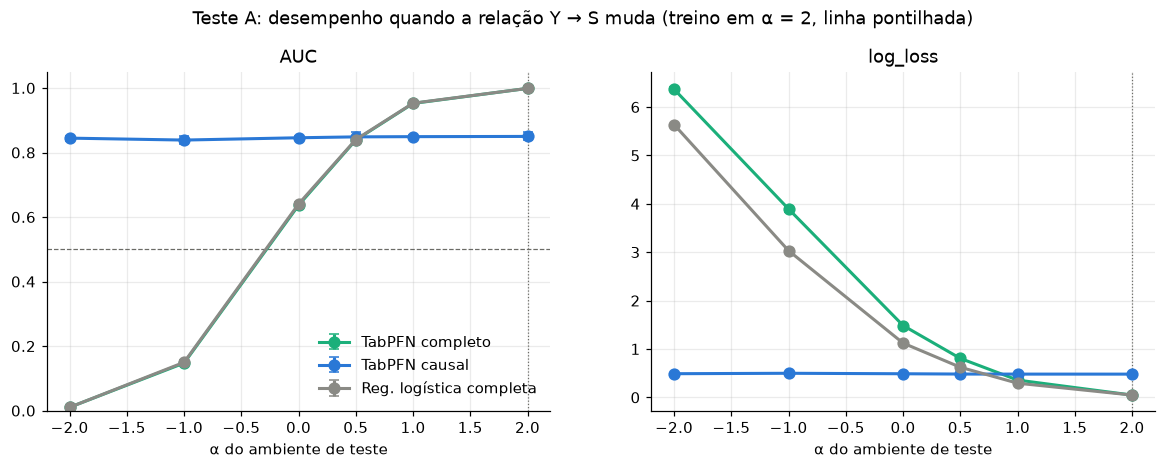

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, met in [(axs[0], "AUC"), (axs[1], "log_loss")]:
    g = teste_a.groupby(["modelo", "alpha"])[met].agg(["mean", "std"]).reset_index()
    for nome in MODELOS:
        gm = g[g.modelo == nome]
        ax.errorbar(gm.alpha, gm["mean"], yerr=gm["std"], color=COR_MODELO[nome], lw=2,
                    marker="o", ms=7, capsize=3, label=nome)
    ax.axvline(2.0, color="#6b6b66", lw=0.8, ls=":")
    ax.set_xlabel("α do ambiente de teste"); ax.set_title(met)
axs[0].axhline(0.5, color="#6b6b66", lw=0.8, ls="--")
axs[0].set_ylim(0, 1.05); axs[0].legend(frameon=False, loc="lower right")
fig.suptitle("Teste A: desempenho quando a relação Y → S muda (treino em α = 2, linha pontilhada)",
             y=1.02)
salvar_figura("teste_a_desempenho_por_alpha")
plt.show()

## 4. Teste B: intervindo diretamente em S

Pegamos os ambientes **forte** (mesma distribuição do treino) e mexemos **só** na coluna S.
X1, X2, Z e o Y verdadeiro não mudam, então qualquer mudança na previsão vem do uso de S.

| Perturbação | O que faz com S | Correlação S–Y |
|---|---|---|
| negar | $S \to -S$ | inverte o sinal |
| diminuir / aumentar | $S \to c\,S$ | **não muda** (correlação é invariante à escala), mas os valores ficam menores/maiores do que o modelo viu no contexto |
| deslocar | $S \to S + c$ | não muda, mas desloca toda a distribuição |
| ruído | $S \to S + N(0, c^2)$ | enfraquece |
| permutar | embaralha S entre as linhas | some (marginal de S preservada) |
| $do(S = 0)$ | fixa S em 0 | some (S vira constante) |

Além da AUC medimos a **taxa de troca**: a fração de linhas em que a classe prevista muda em
relação à previsão com S original.

In [7]:
PERTURBACOES = {
    "original": None,
    "negar (S → −S)": ("negate", 0.0),
    "diminuir (S × 0,5)": ("scale", 0.5),
    "aumentar (S × 2)": ("scale", 2.0),
    "deslocar (S + 2)": ("shift", 2.0),
    "ruído (S + N(0, 2²))": ("noise", 2.0),
    "permutar S": ("permute", 0.0),
    "do(S = 0)": ("constant", 0.0),
}
forte = ambientes[ambientes.ambiente == "forte"]


def aplicar(X, perturbacao, seed=SEED):
    if perturbacao is None:
        return X
    tipo, valor = perturbacao
    return perturb_feature(X, ESPURIA, tipo, valor, random_state=seed)


linhas = []
for seed, d in tqdm(forte.groupby("seed"), total=forte.seed.nunique(), desc="Teste B"):
    p_orig = {nome: prob_y1(m, d[cols]) for nome, (m, cols) in MODELOS.items()}
    for pert_nome, pert in PERTURBACOES.items():
        Xp = aplicar(d[FEATURES], pert, seed=SEED + seed)
        for nome, (modelo, cols) in MODELOS.items():
            p = prob_y1(modelo, Xp[cols])
            linhas.append({"perturbação": pert_nome, "seed": seed, "modelo": nome,
                           "corr_S_Y": np.corrcoef(Xp[ESPURIA], d.Y)[0, 1] if Xp[ESPURIA].std() > 0 else 0.0,
                           **metricas(d.Y, p),
                           "taxa_troca": np.mean((p > 0.5) != (p_orig[nome] > 0.5))})
teste_b = pd.DataFrame(linhas)
teste_b.to_csv(RESULTADOS / "teste_b_intervencoes.csv", index=False)

tab_b = teste_b.pivot_table(index="perturbação", columns="modelo",
                            values=["AUC", "taxa_troca"], sort=False)
tab_b.insert(0, ("corr_S_Y", ""), teste_b.groupby("perturbação", sort=False).corr_S_Y.mean())
tab_b

Teste B:   0%|                                                                       | 0/5 [00:00<?, ?it/s]

Teste B:  20%|████████████▌                                                  | 1/5 [01:36<06:25, 96.47s/it]

Teste B:  40%|█████████████████████████▏                                     | 2/5 [03:14<04:51, 97.12s/it]

Teste B:  60%|█████████████████████████████████████▊                         | 3/5 [04:55<03:18, 99.15s/it]

Teste B:  80%|██████████████████████████████████████████████████▍            | 4/5 [06:31<01:38, 98.03s/it]

Teste B: 100%|███████████████████████████████████████████████████████████████| 5/5 [08:09<00:00, 97.86s/it]

Teste B: 100%|███████████████████████████████████████████████████████████████| 5/5 [08:09<00:00, 97.90s/it]

corr_S_Y             AUC                \
modelo                        TabPFN completo TabPFN causal   
perturbação                                                   
original               0.8942          0.9987        0.8498   
negar (S → −S)        -0.8942          0.0101        0.8498   
diminuir (S × 0,5)     0.8942          0.9984        0.8498   
aumentar (S × 2)       0.8942          0.9969        0.8498   
deslocar (S + 2)       0.8942          0.9958        0.8498   
ruído (S + N(0, 2²))   0.6711          0.9190        0.8498   
permutar S             0.0078          0.6055        0.8498   
do(S = 0)              0.0000          0.8492        0.8498   

                                                  taxa_troca                \
modelo               Reg. logística completa TabPFN completo TabPFN causal   
perturbação                                                                  
original                              0.9987          0.0000        0.0000   
negar (S → −S)                        0.0101          0.9627        0.0000   
diminuir (S × 0,5)                    0.9981          0.0094        0.0000   
aumentar (S × 2)                      0.9985          0.0050        0.0000   
deslocar (S + 2)                      0.9987          0.2144        0.0000   
ruído (S + N(0, 2²))                  0.9216          0.1547        0.0000   
permutar S                            0.5724          0.4770        0.0000   
do(S = 0)                             0.8465          0.2382        0.0000   

                                              
modelo               Reg. logística completa  
perturbação                                   
original                              0.0000  
negar (S → −S)                        0.9557  
diminuir (S × 0,5)                    0.0113  
aumentar (S × 2)                      0.0064  
deslocar (S + 2)                      0.2058  
ruído (S + N(0, 2²))                  0.1519  
permutar S                            0.4739  
do(S = 0)                             0.2341

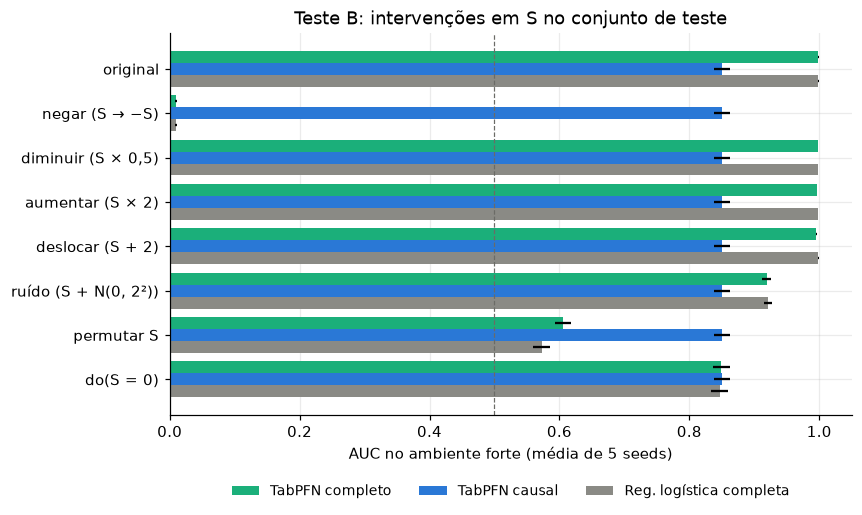

In [8]:
g = teste_b.groupby(["perturbação", "modelo"], sort=False)["AUC"].agg(["mean", "std"]).reset_index()
nomes_pert = list(PERTURBACOES)
y = np.arange(len(nomes_pert))
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, nome in enumerate(MODELOS):
    gm = g[g.modelo == nome].set_index("perturbação").loc[nomes_pert]
    ax.barh(y + (k - 1) * 0.27, gm["mean"], xerr=gm["std"], height=0.27,
            color=COR_MODELO[nome], label=nome)
ax.axvline(0.5, color="#6b6b66", lw=0.8, ls="--")
ax.set_yticks(y, nomes_pert); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
ax.set_xlabel("AUC no ambiente forte (média de 5 seeds)")
ax.set_title("Teste B: intervenções em S no conjunto de teste")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3, fontsize=9)
salvar_figura("teste_b_intervencoes_em_S")
plt.show()

### Curva de intervenção $do(S = s)$

No SCM, S é **efeito** de Y: fixar S em qualquer valor **não muda** Y. Então um modelo alinhado
com a causalidade deveria dar a mesma probabilidade média para qualquer $s$. Fixamos S = s em
todas as linhas do ambiente forte (seed 0) e olhamos a probabilidade média prevista de Y = 1.

do(S = s): TabPFN completo:   0%|                                                   | 0/17 [00:00<?, ?it/s]

do(S = s): TabPFN completo:   6%|██▌                                        | 1/17 [00:05<01:23,  5.20s/it]

do(S = s): TabPFN completo:  12%|█████                                      | 2/17 [00:10<01:17,  5.17s/it]

do(S = s): TabPFN completo:  18%|███████▌                                   | 3/17 [00:15<01:12,  5.15s/it]

do(S = s): TabPFN completo:  24%|██████████                                 | 4/17 [00:20<01:07,  5.15s/it]

do(S = s): TabPFN completo:  29%|████████████▋                              | 5/17 [00:25<01:01,  5.15s/it]

... (30 outputs left out)

do(S = s): TabPFN causal: 100%|████████████████████████████████████████████| 17/17 [01:25<00:00,  5.04s/it]

do(S = s): TabPFN causal: 100%|████████████████████████████████████████████| 17/17 [01:25<00:00,  5.05s/it]

do(S = s): Reg. logística completa:   0%|                                           | 0/17 [00:00<?, ?it/s]

do(S = s): Reg. logística completa: 100%|████████████████████████████████| 17/17 [00:00<00:00, 1041.36it/s]

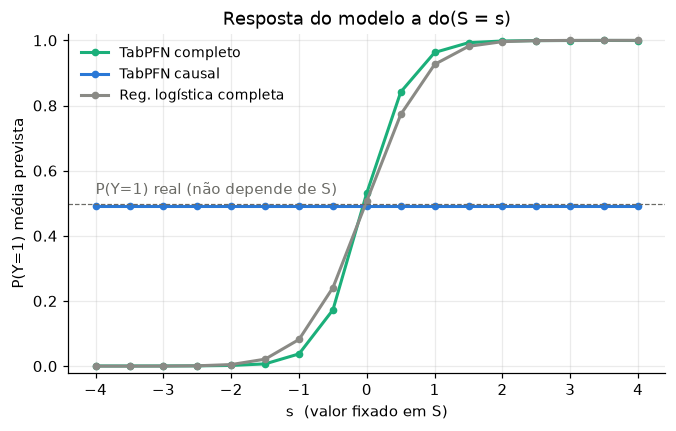

In [9]:
valores_s = np.linspace(-4, 4, 17)
d0 = forte[forte.seed == 0]
curva = pd.DataFrame({
    nome: [prob_y1(m, perturb_feature(d0[FEATURES], ESPURIA, "constant", s)[cols]).mean()
           for s in tqdm(valores_s, desc=f"do(S = s): {nome}")]
    for nome, (m, cols) in MODELOS.items()
}, index=pd.Index(valores_s, name="s"))
curva.to_csv(RESULTADOS / "curva_do_S.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for nome in MODELOS:
    ax.plot(curva.index, curva[nome], color=COR_MODELO[nome], lw=2, marker="o", ms=4, label=nome)
ax.axhline(d0.Y.mean(), color="#6b6b66", lw=0.8, ls="--")
ax.text(-4, d0.Y.mean() + 0.03, "P(Y=1) real (não depende de S)", color="#6b6b66")
ax.set_xlabel("s  (valor fixado em S)"); ax.set_ylabel("P(Y=1) média prevista")
ax.set_ylim(-0.02, 1.02); ax.set_title("Resposta do modelo a do(S = s)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
salvar_figura("curva_do_S")
plt.show()

## 5. SHAP

Usamos SHAP **exato** (4 atributos → 16 coalizões) com valores intervencionais: para "remover"
um atributo, ele é trocado por valores do conjunto de treino (background). A função
`compute_shap_values` dá o mesmo resultado que o `shap.ExactExplainer`, mas avalia todas as
coalizões em poucas chamadas ao TabPFN.

Os valores explicam $P(Y = 1 \mid x)$, então somam a previsão menos a média do background.

### 5.1 Modelo fixo (treino α = 2) explicado em cada teste

O modelo é o mesmo em todos os cenários; só os dados de entrada mudam. Além da importância
média $|\text{SHAP}|$, medimos se a contribuição de S **aponta para a classe verdadeira**
(sinal de SHAP de S igual ao sinal de $2Y - 1$).

In [10]:
def amostra(df, n=N_EXPLICAR, seed=SEED):
    return df.sample(n=min(n, len(df)), random_state=seed)


def por_amb(nome, seed=0):
    return ambientes[(ambientes.ambiente == nome) & (ambientes.seed == seed)]


base_forte = amostra(por_amb("forte"))
CENARIOS = {
    "forte (α = 2)": base_forte,
    "fraco (α = 0,5)": amostra(por_amb("fraco")),
    "nulo (α = 0)": amostra(por_amb("nulo")),
    "invertido (α = −2)": amostra(por_amb("invertido")),
    "forte + negar S": base_forte.assign(S=-base_forte.S),
    "forte + permutar S": base_forte.assign(
        S=perturb_feature(base_forte[FEATURES], ESPURIA, "permute", random_state=SEED).S),
}

explicacoes, linhas = {}, []
for cen, d in tqdm(CENARIOS.items(), total=len(CENARIOS), desc="SHAP 5.1"):
    exp = compute_shap_values(modelo_completo, d[FEATURES], treino[FEATURES],
                              n_background=N_FUNDO, random_state=SEED)
    explicacoes[cen] = exp
    imp = shap_importance(exp)
    shap_s = exp.values[:, FEATURES.index(ESPURIA)]
    linhas.append({"cenário": cen, **imp[FEATURES].to_dict(),
                   "fração_S": imp[ESPURIA] / imp.sum(),
                   "S_a_favor_da_classe_real": np.mean(np.sign(shap_s) == np.sign(2 * d.Y.values - 1)),
                   "causal_precision@2": causal_precision_at_k(imp, CAUSAS)})
shap_51 = pd.DataFrame(linhas).set_index("cenário")
shap_51.to_csv(RESULTADOS / "shap_modelo_fixo.csv")
shap_51

SHAP 5.1:   0%|                                                                      | 0/6 [00:00<?, ?it/s]

SHAP 5.1:  17%|██████████▎                                                   | 1/6 [01:16<06:22, 76.55s/it]

SHAP 5.1:  33%|████████████████████▋                                         | 2/6 [02:36<05:13, 78.40s/it]

SHAP 5.1:  50%|███████████████████████████████                               | 3/6 [03:54<03:54, 78.19s/it]

SHAP 5.1:  67%|█████████████████████████████████████████▎                    | 4/6 [05:13<02:36, 78.48s/it]

SHAP 5.1:  83%|███████████████████████████████████████████████████▋          | 5/6 [06:34<01:19, 79.46s/it]

SHAP 5.1: 100%|██████████████████████████████████████████████████████████████| 6/6 [07:53<00:00, 79.48s/it]

SHAP 5.1: 100%|██████████████████████████████████████████████████████████████| 6/6 [07:53<00:00, 78.97s/it]

,X1,X2,S,Z,fração_S,S_a_favor_da_classe_real,causal_precision@2
cenário,,,,,,,
forte (α = 2),0.0205,0.0112,0.4745,0.0002,0.9371,0.9600,0.5000
"fraco (α = 0,5)",0.0579,0.0320,0.3619,0.0004,0.8002,0.7300,0.5000
nulo (α = 0),0.0671,0.0471,0.3530,0.0006,0.7546,0.4900,0.5000
invertido (α = −2),0.0227,0.0150,0.4553,0.0002,0.9232,0.0400,0.5000
forte + negar S,0.0237,0.0153,0.4552,0.0002,0.9207,0.0500,0.5000
forte + permutar S,0.0227,0.0136,0.4781,0.0002,0.9289,0.5500,0.5000


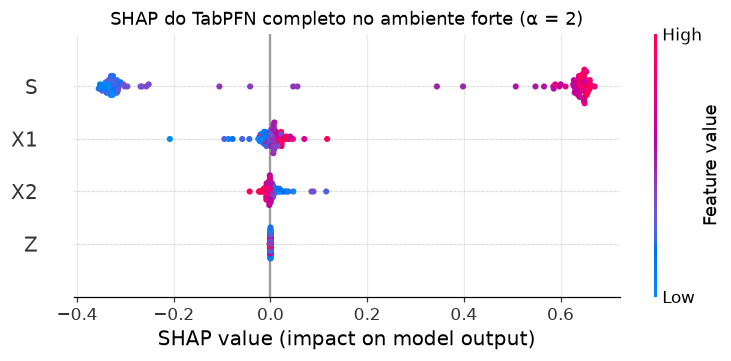

In [11]:
shap.plots.beeswarm(explicacoes["forte (α = 2)"], show=False)
plt.title("SHAP do TabPFN completo no ambiente forte (α = 2)")
salvar_figura("shap_beeswarm_forte")
plt.show()

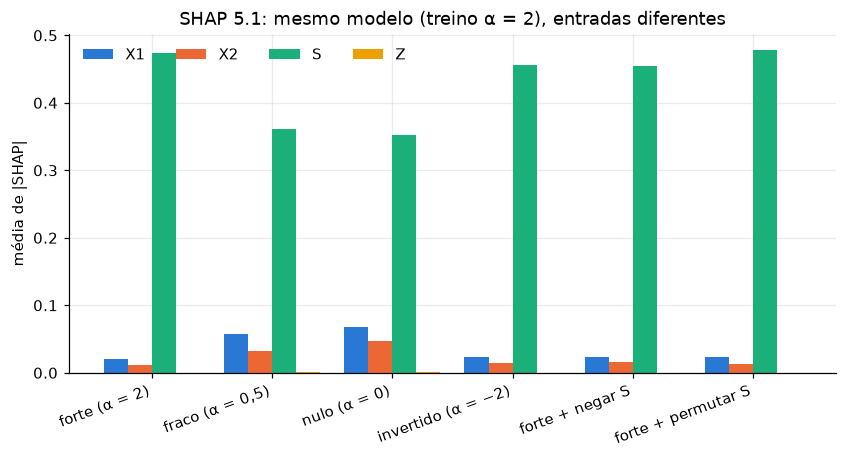

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
cen = list(shap_51.index)
x = np.arange(len(cen))
for k, f in enumerate(FEATURES):
    ax.bar(x + (k - 1.5) * 0.2, shap_51[f], width=0.2, color=COR[f], label=f)
ax.set_xticks(x, cen, rotation=20, ha="right")
ax.set_ylabel("média de |SHAP|")
ax.set_title("SHAP 5.1: mesmo modelo (treino α = 2), entradas diferentes")
ax.legend(frameon=False, ncols=4)
salvar_figura("shap_modelo_fixo")
plt.show()

### 5.2 Contexto em cada ambiente

Agora o TabPFN recebe como contexto os dados **de cada ambiente** (metade das linhas da seed 0) e é
explicado na outra metade do mesmo ambiente. Isso mostra quanto o modelo escolhe S como atalho
conforme a força α da relação espúria disponível no contexto.

In [13]:
linhas = []
for amb, alpha in tqdm(list(ORDEM_AMB.itertuples(index=False)), desc="SHAP 5.2"):
    d = por_amb(amb).sample(frac=1, random_state=SEED)
    contexto, teste = d.iloc[: len(d) // 2], d.iloc[len(d) // 2 :]
    modelo = novo_tabpfn().fit(contexto[FEATURES], contexto.Y)
    exp = compute_shap_values(modelo, amostra(teste)[FEATURES], contexto[FEATURES],
                              n_background=N_FUNDO, random_state=SEED)
    imp = shap_importance(exp)
    linhas.append({"ambiente": amb, "alpha": alpha,
                   "AUC (mesmo ambiente)": roc_auc_score(teste.Y, prob_y1(modelo, teste[FEATURES])),
                   **(imp / imp.sum())[FEATURES].add_prefix("fração_").to_dict(),
                   "causal_precision@2": causal_precision_at_k(imp, CAUSAS)})
shap_52 = pd.DataFrame(linhas).set_index(["ambiente", "alpha"])
shap_52.to_csv(RESULTADOS / "shap_contexto_por_ambiente.csv")
shap_52

SHAP 5.2:   0%|                                                                      | 0/6 [00:00<?, ?it/s]

SHAP 5.2:  17%|██████████▎                                                   | 1/6 [01:02<05:13, 62.61s/it]

SHAP 5.2:  33%|████████████████████▋                                         | 2/6 [02:03<04:05, 61.48s/it]

SHAP 5.2:  50%|███████████████████████████████                               | 3/6 [03:02<03:01, 60.41s/it]

SHAP 5.2:  67%|█████████████████████████████████████████▎                    | 4/6 [04:04<02:02, 61.08s/it]

SHAP 5.2:  83%|███████████████████████████████████████████████████▋          | 5/6 [05:06<01:01, 61.24s/it]

SHAP 5.2: 100%|██████████████████████████████████████████████████████████████| 6/6 [06:07<00:00, 61.25s/it]

SHAP 5.2: 100%|██████████████████████████████████████████████████████████████| 6/6 [06:07<00:00, 61.22s/it]

,,AUC (mesmo ambiente),fração_X1,fração_X2,fração_S,fração_Z,causal_precision@2
ambiente,alpha,,,,,,
forte,2.0000,0.9979,0.0501,0.0274,0.9221,0.0004,0.5000
médio,1.0000,0.9597,0.2825,0.1426,0.5731,0.0017,0.5000
fraco,0.5000,0.8884,0.4175,0.2798,0.2844,0.0182,0.5000
nulo,0.0000,0.8484,0.6042,0.3628,0.0247,0.0084,1.0000
invertido fraco,-1.0000,0.9559,0.2016,0.1036,0.6902,0.0046,0.5000
invertido,-2.0000,0.9990,0.0393,0.0296,0.9304,0.0007,0.5000


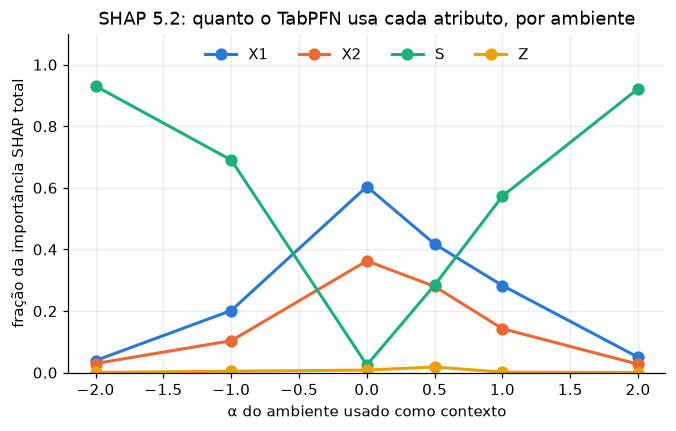

In [14]:
g = shap_52.reset_index().sort_values("alpha")
fig, ax = plt.subplots(figsize=(7, 4))
for f in FEATURES:
    ax.plot(g.alpha, g[f"fração_{f}"], color=COR[f], lw=2, marker="o", ms=7, label=f)
ax.legend(frameon=False, loc="upper center", ncols=4)
ax.set_xlabel("α do ambiente usado como contexto")
ax.set_ylabel("fração da importância SHAP total")
ax.set_ylim(0, 1.1); ax.set_title("SHAP 5.2: quanto o TabPFN usa cada atributo, por ambiente")
salvar_figura("shap_contexto_por_ambiente")
plt.show()

## 6. Contrafactuais: comparando com o efeito causal verdadeiro

Como os dados vêm de um SCM, sabemos a **probabilidade causal verdadeira**:

$$P(Y = 1 \mid X_1, X_2) = \sigma(1{,}5\,X_1 - 1{,}0\,X_2)$$

S e Z não aparecem nela. Isso permite comparar o modelo com a verdade, não só com o Y observado.

### 6.1 Probabilidade prevista vs. verdadeira

Para cada ambiente, o erro médio $|\hat p - p_{\text{verdadeira}}|$. Um modelo alinhado com a
causalidade deveria ter o mesmo erro em todos os ambientes, porque $p_{\text{verdadeira}}$ não depende de α.

In [15]:
linhas = []
grupos = ambientes.groupby(["ambiente", "alpha", "seed"], sort=False)
for (amb, alpha, seed), d in tqdm(grupos, total=grupos.ngroups, desc="6.1 prob. verdadeira"):
    p_true = logistic_scm_probability(d)
    for nome, (modelo, cols) in MODELOS.items():
        p = prob_y1(modelo, d[cols])
        linhas.append({"ambiente": amb, "alpha": alpha, "seed": seed, "modelo": nome,
                       "erro_medio_p": np.mean(np.abs(p - p_true)),
                       "corr_p": np.corrcoef(p, p_true)[0, 1]})
cf_61 = pd.DataFrame(linhas)
cf_61.to_csv(RESULTADOS / "contrafactual_prob_verdadeira.csv", index=False)

(cf_61.pivot_table(index=["ambiente", "alpha"], columns="modelo", values="erro_medio_p", sort=False)
 [list(MODELOS)].sort_index(level="alpha", ascending=False))

6.1 prob. verdadeira:   0%|                                                         | 0/30 [00:00<?, ?it/s]

6.1 prob. verdadeira:   3%|█▋                                               | 1/30 [00:12<05:59, 12.41s/it]

6.1 prob. verdadeira:   7%|███▎                                             | 2/30 [00:24<05:36, 12.00s/it]

6.1 prob. verdadeira:  10%|████▉                                            | 3/30 [00:35<05:19, 11.83s/it]

6.1 prob. verdadeira:  13%|██████▌                                          | 4/30 [00:47<05:05, 11.76s/it]

6.1 prob. verdadeira:  17%|████████▏                                        | 5/30 [00:59<04:53, 11.73s/it]

... (23 outputs left out)

6.1 prob. verdadeira:  97%|██████████████████████████████████████████████▍ | 29/30 [05:27<00:11, 11.45s/it]

6.1 prob. verdadeira: 100%|████████████████████████████████████████████████| 30/30 [05:39<00:00, 11.62s/it]

6.1 prob. verdadeira: 100%|████████████████████████████████████████████████| 30/30 [05:39<00:00, 11.31s/it]

,modelo,TabPFN completo,TabPFN causal,Reg. logística completa
ambiente,alpha,,,
forte,2.0000,0.3077,0.0150,0.2983
médio,1.0000,0.2945,0.0150,0.2689
fraco,0.5000,0.3054,0.0149,0.2722
nulo,0.0000,0.3464,0.0150,0.3073
invertido fraco,-1.0000,0.5044,0.0147,0.4696
invertido,-2.0000,0.6277,0.0149,0.6111


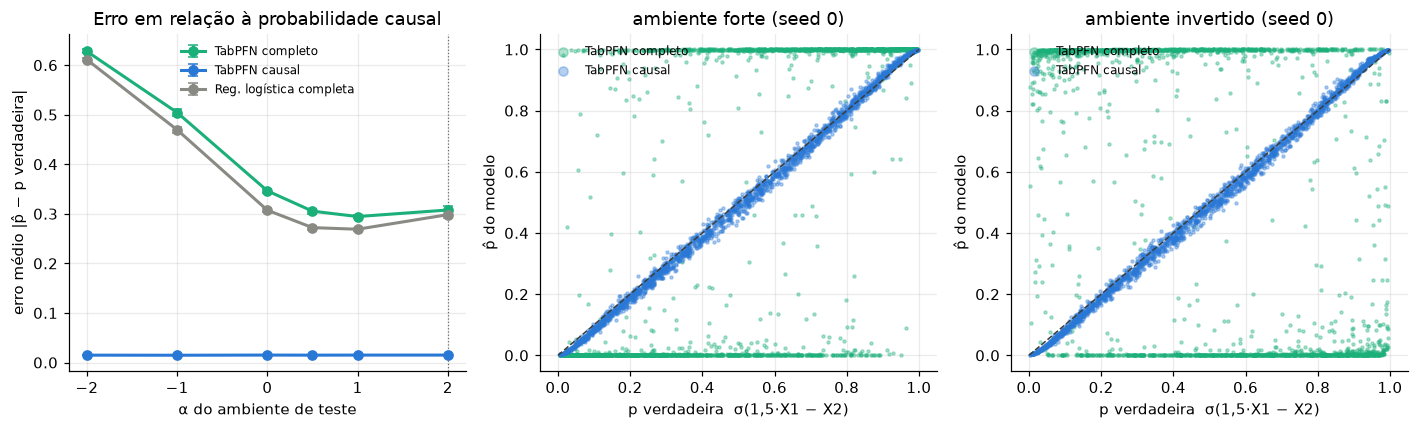

In [16]:
fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(1, 3, 1)
g = cf_61.groupby(["modelo", "alpha"])["erro_medio_p"].agg(["mean", "std"]).reset_index()
for nome in MODELOS:
    gm = g[g.modelo == nome]
    ax.errorbar(gm.alpha, gm["mean"], yerr=gm["std"], color=COR_MODELO[nome], lw=2,
                marker="o", ms=6, capsize=3, label=nome)
ax.axvline(2.0, color="#6b6b66", lw=0.8, ls=":")
ax.set_xlabel("α do ambiente de teste"); ax.set_ylabel("erro médio |p̂ − p verdadeira|")
ax.set_title("Erro em relação à probabilidade causal"); ax.legend(frameon=False, fontsize=8)

for k, amb in enumerate(["forte", "invertido"]):
    ax = fig.add_subplot(1, 3, k + 2)
    d = por_amb(amb)
    p_true = logistic_scm_probability(d)
    for nome in ["TabPFN completo", "TabPFN causal"]:
        modelo, cols = MODELOS[nome]
        ax.scatter(p_true, prob_y1(modelo, d[cols]), s=4, alpha=0.35, color=COR_MODELO[nome],
                   label=nome)
    ax.plot([0, 1], [0, 1], color="#3d3d3a", lw=1, ls="--")
    ax.set_xlabel("p verdadeira  σ(1,5·X1 − X2)"); ax.set_ylabel("p̂ do modelo")
    ax.set_title(f"ambiente {amb} (seed 0)")
    ax.legend(frameon=False, fontsize=8, markerscale=3, loc="upper left")
plt.tight_layout()
salvar_figura("contrafactual_prob_verdadeira")
plt.show()

### 6.2 Curvas $do(X_1 = x)$ e $do(X_2 = x)$

Fixamos uma causa em vários valores e comparamos a probabilidade média prevista com a verdadeira,
$P(Y = 1 \mid do(X_1 = x)) = \mathbb{E}_{X_2}[\sigma(1{,}5\,x - X_2)]$. Há dois jeitos de montar a
entrada do modelo:

* **S congelado**: só a coluna intervinda muda (o que um gráfico de dependência parcial faz).
  S continua refletindo o Y antigo, o que não aconteceria no mundo real, já que S é efeito de Y.
* **S propagado pelo SCM**: contrafactual completo (`prototype_counterfactual`). Abdução: recupera
  os ruídos $\varepsilon_S$ e $\varepsilon_Y$ de cada linha. Ação: aplica $do(X_1 = x)$. Predição:
  recalcula Y e depois S com os mesmos ruídos.

Um modelo que usa as causas deveria seguir a curva verdadeira nos dois casos. Um modelo que usa S
só consegue segui-la quando S é propagado, porque aí S já "carrega" o novo Y.

6.2 curvas do(X):   0%|                                                             | 0/22 [00:00<?, ?it/s]

6.2 curvas do(X):   5%|██▍                                                  | 1/22 [00:15<05:17, 15.11s/it]

6.2 curvas do(X):   9%|████▊                                                | 2/22 [00:30<05:00, 15.02s/it]

6.2 curvas do(X):  14%|███████▏                                             | 3/22 [00:44<04:42, 14.85s/it]

6.2 curvas do(X):  18%|█████████▋                                           | 4/22 [00:59<04:29, 14.95s/it]

6.2 curvas do(X):  23%|████████████                                         | 5/22 [01:14<04:14, 14.98s/it]

... (14 outputs left out)

6.2 curvas do(X):  91%|███████████████████████████████████████████████▎    | 20/22 [05:01<00:30, 15.06s/it]

6.2 curvas do(X):  95%|█████████████████████████████████████████████████▋  | 21/22 [05:16<00:14, 14.95s/it]

6.2 curvas do(X): 100%|████████████████████████████████████████████████████| 22/22 [05:30<00:00, 14.88s/it]

6.2 curvas do(X): 100%|████████████████████████████████████████████████████| 22/22 [05:30<00:00, 15.04s/it]

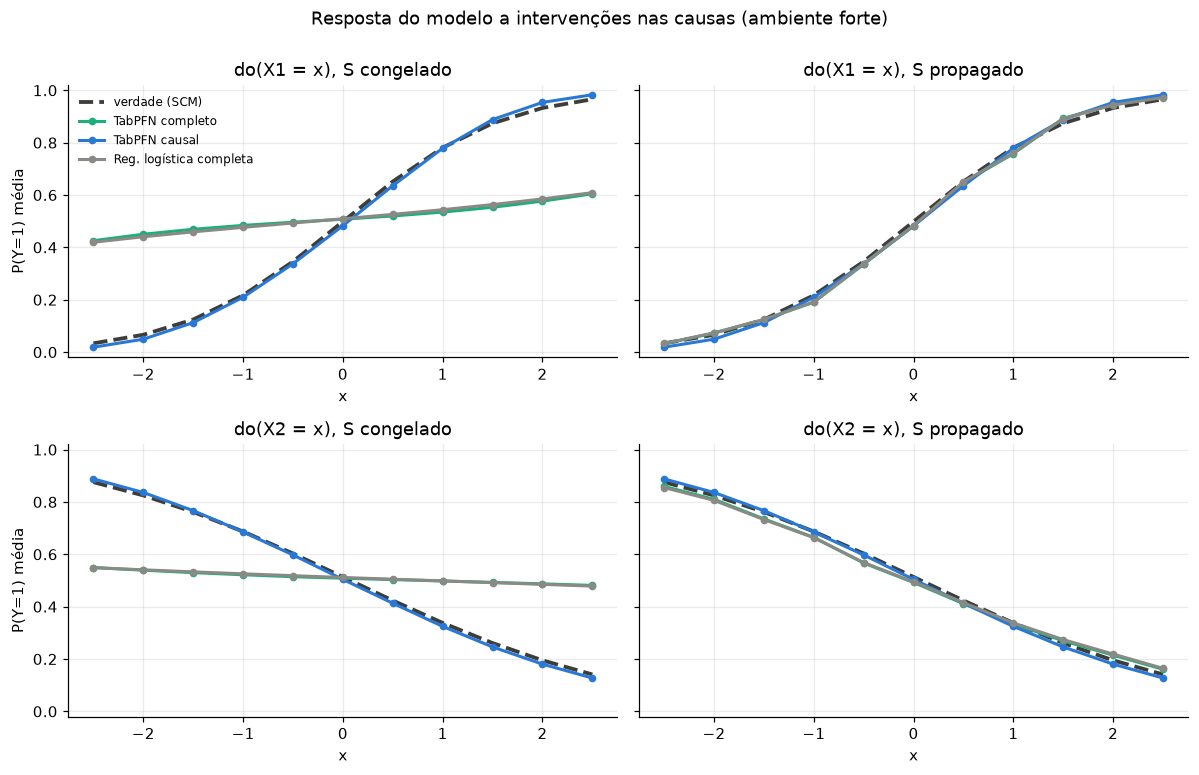

In [17]:
ALPHA_FORTE = 2.0
d_cf = amostra(por_amb("forte"), n=N_CONTRAFACTUAL)
grade = np.linspace(-2.5, 2.5, 11)

linhas = []
for var, x in tqdm([(v, x) for v in CAUSAS for x in grade], desc="6.2 curvas do(X)"):
    congelado = d_cf.assign(**{var: x})
    propagado = prototype_counterfactual(d_cf, ALPHA_FORTE, {var: x}, random_state=SEED)
    verdade = logistic_scm_probability(congelado).mean()
    for nome, (modelo, cols) in MODELOS.items():
        linhas.append({"variável": var, "x": x, "modelo": nome, "verdade": verdade,
                       "S congelado": prob_y1(modelo, congelado[cols]).mean(),
                       "S propagado": prob_y1(modelo, propagado[cols]).mean()})
cf_62 = pd.DataFrame(linhas)
cf_62.to_csv(RESULTADOS / "contrafactual_curvas_do.csv", index=False)

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for i, var in enumerate(CAUSAS):
    for j, modo in enumerate(["S congelado", "S propagado"]):
        ax = axs[i, j]
        cv = cf_62[cf_62["variável"] == var]
        verdade = cv.drop_duplicates("x")
        ax.plot(verdade.x, verdade.verdade, color="#3d3d3a", lw=2.5, ls="--", label="verdade (SCM)")
        for nome in MODELOS:
            cm = cv[cv.modelo == nome]
            ax.plot(cm.x, cm[modo], color=COR_MODELO[nome], lw=2, marker="o", ms=4, label=nome)
        ax.set_title(f"do({var} = x), {modo}")
        ax.set_xlabel("x"); ax.set_ylim(-0.02, 1.02)
    axs[i, 0].set_ylabel("P(Y=1) média")
axs[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Resposta do modelo a intervenções nas causas (ambiente forte)", y=1.0)
plt.tight_layout()
salvar_figura("contrafactual_curvas_do")
plt.show()

### 6.3 Efeito individual de mexer em uma causa

Para cada linha aplicamos $do(X_j = X_j + 1)$ e comparamos a mudança prevista
$\Delta\hat p_i$ com a mudança verdadeira $\Delta p_i = \sigma(\text{logit}_i') - \sigma(\text{logit}_i)$.
No modo "S propagado", S carrega o Y contrafactual sorteado, então o erro individual também inclui o
ruído de $\varepsilon_Y$; a comparação mais justa ali é a do **Δp médio**.

In [18]:
linhas = []
for var in tqdm(CAUSAS, desc="6.3 efeito individual"):
    novo = (d_cf[var] + 1.0).to_numpy()
    dp_true = (logistic_scm_probability(d_cf.assign(**{var: novo}))
               - logistic_scm_probability(d_cf)).to_numpy()
    entradas = {
        "S congelado": d_cf.assign(**{var: novo}),
        "S propagado": prototype_counterfactual(d_cf, ALPHA_FORTE, {var: novo}, random_state=SEED),
    }
    for nome, (modelo, cols) in MODELOS.items():
        p0 = prob_y1(modelo, d_cf[cols])
        for modo, Xc in entradas.items():
            dp = prob_y1(modelo, Xc[cols]) - p0
            linhas.append({"intervenção": f"do({var} = {var} + 1)", "modo": modo, "modelo": nome,
                           "Δp médio (modelo)": dp.mean(), "Δp médio (verdade)": dp_true.mean(),
                           "erro médio |Δp̂ − Δp|": np.mean(np.abs(dp - dp_true)),
                           "corr(Δp̂, Δp)": np.corrcoef(dp, dp_true)[0, 1] if dp.std() > 0 else np.nan})
cf_63 = pd.DataFrame(linhas)
cf_63.to_csv(RESULTADOS / "contrafactual_efeito_individual.csv", index=False)

tab_63 = cf_63.pivot_table(index=["intervenção", "modelo"], columns="modo", sort=False,
                           values=["Δp médio (modelo)", "erro médio |Δp̂ − Δp|"])
tab_63.insert(0, ("Δp médio (verdade)", ""),
              cf_63.groupby(["intervenção", "modelo"], sort=False)["Δp médio (verdade)"].first())
tab_63

6.3 efeito individual:   0%|                                                         | 0/2 [00:00<?, ?it/s]

6.3 efeito individual:  50%|████████████████████████▌                        | 1/2 [00:21<00:21, 21.81s/it]

6.3 efeito individual: 100%|█████████████████████████████████████████████████| 2/2 [00:43<00:00, 21.93s/it]

6.3 efeito individual: 100%|█████████████████████████████████████████████████| 2/2 [00:43<00:00, 21.91s/it]

Δp médio (verdade) Δp médio (modelo)  \
modo                                                             S congelado   
intervenção     modelo                                                         
do(X1 = X1 + 1) TabPFN completo                     0.2340            0.0223   
                TabPFN causal                       0.2340            0.2439   
                Reg. logística completa             0.2340            0.0279   
do(X2 = X2 + 1) TabPFN completo                    -0.1618           -0.0106   
                TabPFN causal                      -0.1618           -0.1654   
                Reg. logística completa            -0.1618           -0.0127   

                                                    erro médio |Δp̂ − Δp|  \
modo                                    S propagado           S congelado   
intervenção     modelo                                                      
do(X1 = X1 + 1) TabPFN completo              0.2091                0.2211   
                TabPFN causal                0.2439                0.0194   
                Reg. logística completa      0.2080                0.2110   
do(X2 = X2 + 1) TabPFN completo             -0.1597                0.1534   
                TabPFN causal               -0.1654                0.0137   
                Reg. logística completa     -0.1574                0.1498   

                                                     
modo                                    S propagado  
intervenção     modelo                               
do(X1 = X1 + 1) TabPFN completo              0.3049  
                TabPFN causal                0.0194  
                Reg. logística completa      0.2925  
do(X2 = X2 + 1) TabPFN completo              0.2423  
                TabPFN causal                0.0137  
                Reg. logística completa      0.2353

## 7. Pontos para a análise dos resultados

Perguntas para o grupo responder olhando as tabelas e gráficos acima (os CSVs ficam em
`results/prototipo/` e os gráficos em `results/prototipo/figuras/`):

1. **Teste A**: quanto a AUC do TabPFN completo cai de α = 2 para α = 0 e α = −2? Ele cai
   mais ou menos que a regressão logística? A partir de qual α ele fica pior que o TabPFN causal?
2. **Teste B**: quais intervenções em S derrubam o desempenho? "Diminuir" e "aumentar" não mudam
   a correlação; o modelo reage mesmo assim (usa a magnitude de S)? A taxa de troca do
   TabPFN completo em "negar" e "permutar" é alta?
3. **Curva do(S = s)**: a curva do TabPFN completo é plana (como no SCM) ou varia com s?
4. **SHAP 5.1**: no ambiente forte, S tem a maior importância? Nos ambientes invertido / negar S,
   a contribuição de S passa a apontar para a classe errada (`S_a_favor_da_classe_real` perto de 0)?
5. **SHAP 5.2**: a fração de S cresce com |α|? Quando α = 0, o modelo ignora S e Z e fica só
   com X1 e X2 (`causal_precision@2` = 1)?
6. **Contrafactual 6.1**: o erro em relação à probabilidade causal verdadeira fica estável entre
   ambientes, ou cresce quando α se afasta de 2?
7. **Contrafactual 6.2 / 6.3**: com S congelado, o TabPFN completo segue a curva verdadeira de
   do(X1) e do(X2), ou fica achatado? Ele só acerta o Δp médio quando S é propagado (isto é, acerta
   pelo motivo errado)?